# Horse Colic — exploración descriptiva

Estudio de portafolio de Ariel Aravena, preparado con asistencia de Codex. Datos de UCI, CC BY 4.0; ver data/ATRIBUCION.md.
Esta exploración describe faltantes, tipos y distribución. No produce el CSV transformado usado para evaluar modelos: el modelado ajusta sus transformaciones dentro de cada fold. No demuestra utilidad clínica.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
RESULTS = BASE/'resultados'; RESULTS.mkdir(exist_ok=True)
DATA = BASE/'data/horse-colic.data'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == '270db486c78796143ffa84b4808118b3d4b96d1bd0f70bf22b3bb0bfca21e547'
columns = ['surgery', 'age', 'hospital_number', 'rectal_temperature', 'pulse', 'respiratory_rate', 'temp_extremities', 'peripheral_pulse', 'mucous_membranes', 'capillary_refill_time', 'pain', 'peristalsis', 'abdominal_distension', 'nasogastric_tube', 'nasogastric_reflux', 'nasogastric_reflux_ph', 'rectal_exam_feces', 'abdomen', 'packed_cell_volume', 'total_protein', 'abdomcentesis_appearance', 'abdomcentesis_total_protein', 'outcome', 'surgical_lesion', 'lesion_1', 'lesion_2', 'lesion_3', 'cp_data']
raw = pd.read_csv(DATA, sep=r'\s+', header=None, names=columns, na_values='?')
assert raw.shape == (300,28)
display(raw.head())
display(raw.describe().T)


,surgery,age,hospital_number,rectal_temperature,pulse,respiratory_rate,temp_extremities,peripheral_pulse,mucous_membranes,capillary_refill_time,pain,peristalsis,abdominal_distension,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomcentesis_appearance,abdomcentesis_total_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,2.0,1,530101,38.5,66.0,28.0,3.0,3.0,NaN,2.0,5.0,4.0,4.0,NaN,NaN,NaN,3.0,5.0,45.0,8.4,NaN,NaN,2.0,2,11300,0,0,2
1,1.0,1,534817,39.2,88.0,20.0,NaN,NaN,4.0,1.0,3.0,4.0,2.0,NaN,NaN,NaN,4.0,2.0,50.0,85.0,2.0,2.0,3.0,2,2208,0,0,2
2,2.0,1,530334,38.3,40.0,24.0,1.0,1.0,3.0,1.0,3.0,3.0,1.0,NaN,NaN,NaN,1.0,1.0,33.0,6.7,NaN,NaN,1.0,2,0,0,0,1
3,1.0,9,5290409,39.1,164.0,84.0,4.0,1.0,6.0,2.0,2.0,4.0,4.0,1.0,2.0,5.0,3.0,NaN,48.0,7.2,3.0,5.3,2.0,1,2208,0,0,1
4,2.0,1,530255,37.3,104.0,35.0,NaN,NaN,6.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,2.0,2,4300,0,0,2


,count,mean,std,min,25%,50%,75%,max
surgery,299.0,1.397993e+00,4.903046e-01,1.0,1.00,1.00,2.0,2.0
age,300.0,1.640000e+00,2.173972e+00,1.0,1.00,1.00,1.0,9.0
hospital_number,300.0,1.085889e+06,1.529801e+06,518476.0,528904.00,530305.50,534727.5,5305629.0
rectal_temperature,240.0,3.816792e+01,7.322887e-01,35.4,37.80,38.20,38.5,40.8
pulse,276.0,7.191304e+01,2.863056e+01,30.0,48.00,64.00,88.0,184.0
respiratory_rate,242.0,3.041736e+01,1.764223e+01,8.0,18.50,24.50,36.0,96.0
temp_extremities,244.0,2.348361e+00,1.045054e+00,1.0,1.00,3.00,3.0,4.0
peripheral_pulse,231.0,2.017316e+00,1.042428e+00,1.0,1.00,2.00,3.0,4.0
mucous_membranes,253.0,2.853755e+00,1.620294e+00,1.0,1.00,3.00,4.0,6.0
capillary_refill_time,268.0,1.305970e+00,4.776285e-01,1.0,1.00,1.00,2.0,3.0


Identificadores únicos: 284
Filas con ID repetido: 32
Edad, códigos observados: {1: 276, 9: 24}


<ipython-input-2-9198b2a26269>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,faltantes_porcentaje
nasogastric_reflux_ph,82.333333
abdomcentesis_total_protein,66.000000
abdomcentesis_appearance,55.000000
abdomen,39.333333
nasogastric_reflux,35.333333
nasogastric_tube,34.666667
rectal_exam_feces,34.000000
peripheral_pulse,23.000000
rectal_temperature,20.000000
respiratory_rate,19.333333


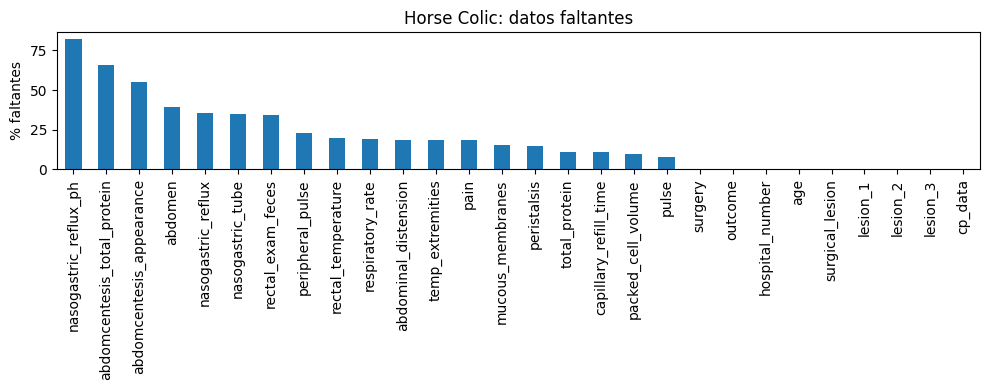

In [2]:
missing = raw.isna().mean().mul(100).sort_values(ascending=False)
display(missing.rename('faltantes_porcentaje').to_frame())
print('Identificadores únicos:', raw.hospital_number.nunique())
print('Filas con ID repetido:', raw.hospital_number.duplicated(keep=False).sum())
print('Edad, códigos observados:', raw.age.value_counts().to_dict())
missing.to_csv(RESULTS/'exploracion_faltantes.csv')
fig, ax = plt.subplots(figsize=(10,4)); missing.plot.bar(ax=ax)
ax.set_ylabel('% faltantes'); ax.set_title('Horse Colic: datos faltantes'); fig.tight_layout()
fig.savefig(RESULTS/'exploracion_faltantes.png',dpi=140)
plt.show()


## Límites

El dataset es pequeño y sus códigos requieren interpretación según el diccionario. Un identificador hospitalario repetido debe permanecer en una sola partición. La imputación global produciría fuga de información si se usara para evaluar modelos; por eso no se exporta un dataset imputado ni escalado desde esta exploración. Las decisiones de variables y selección quedan explícitas en el notebook de modelado.